#### MPAS Regrid-to-Lat/Lon & Difference Map
The standard pattern for comparing two MPAS sources that don't share a grid -- two experiments, two resolutions, or model vs. obs/reanalysis: regrid each onto the same regular lat/lon grid with `scipy.interpolate.griddata`, then difference directly.

Demonstrated here with two forecast times from the same run (a trivial case where both sides happen to share a grid, so the regridding step is not strictly required -- but the code keeps `ds_i_a`/`ds_i_b` and `points_a`/`points_b` separate throughout, so it doesn't matter whether the two sources share a mesh or not). To compare two different experiments or mesh resolutions instead, just point `ds_i_a`/`ds_a` and `ds_i_b`/`ds_b` at the two runs' own grid + diag files; the regrid-and-diff logic below is unchanged.

**Data**: SouthAmerica 240-48km variable-resolution tutorial run, `diag.*.nc` t2m at two valid times 4 days apart.

Ming Ge Nov. 2026

In [1]:
import numpy as np
import xarray as xr
from scipy.interpolate import griddata
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

from mpas_utils import mpas_lonlat_deg

#### Load the two sources to compare

In [2]:
data_dir = '/glade/campaign/mmm/c3we/mingge/MPAS_PROJ/mpas_tutorial/240-48km_variable/'

# kept separate (rather than one shared mesh) so this still works unchanged when the two
# sources are different experiments or resolutions, not just two times from one run
ds_i_a = xr.open_dataset(data_dir + 'SouthAmerica.init.nc')
lon_a, lat_a = mpas_lonlat_deg(ds_i_a['lonCell'].values, ds_i_a['latCell'].values)
points_a = np.column_stack([lon_a, lat_a])

ds_i_b = xr.open_dataset(data_dir + 'SouthAmerica.init.nc')
lon_b, lat_b = mpas_lonlat_deg(ds_i_b['lonCell'].values, ds_i_b['latCell'].values)
points_b = np.column_stack([lon_b, lat_b])

ds_a = xr.open_dataset(data_dir + 'diag.2014-09-10_00.00.00.nc').squeeze()  # t0
ds_b = xr.open_dataset(data_dir + 'diag.2014-09-14_00.00.00.nc').squeeze()  # t0 + 4 days

varname = 't2m'
label_a, label_b = '2014-09-10 00Z', '2014-09-14 00Z'

#### Regrid both onto a common regular lat/lon grid

In [3]:
lon_bounds = (-80, -55)
lat_bounds = (-40, -15)
res_deg = 0.5

glon = np.arange(lon_bounds[0], lon_bounds[1], res_deg)
glat = np.arange(lat_bounds[0], lat_bounds[1], res_deg)
LON, LAT = np.meshgrid(glon, glat)

field_a = griddata(points_a, ds_a[varname].values, (LON, LAT), method='linear')
field_b = griddata(points_b, ds_b[varname].values, (LON, LAT), method='linear')
diff = field_b - field_a

#### Side-by-side + difference

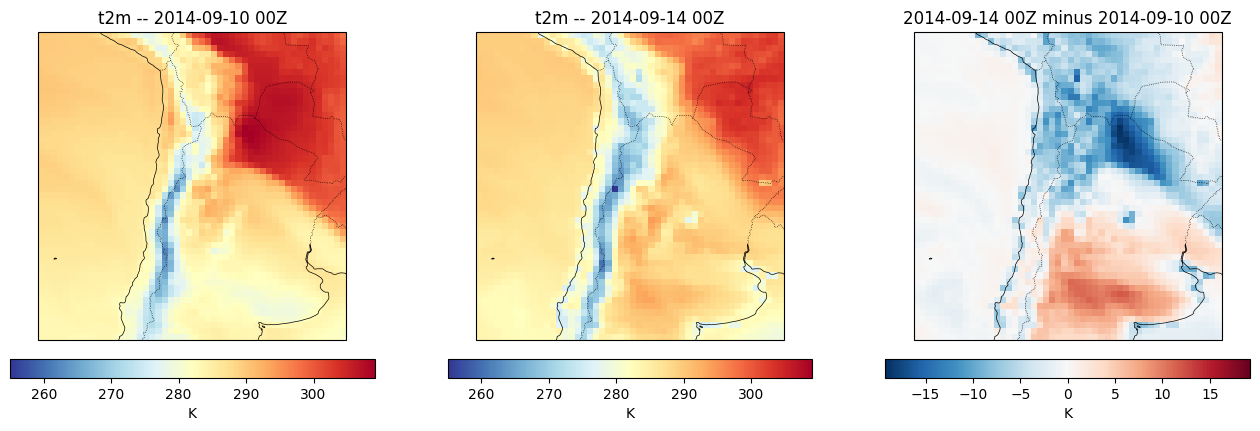

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), subplot_kw={'projection': ccrs.PlateCarree()})

vmin, vmax = np.nanmin([field_a, field_b]), np.nanmax([field_a, field_b])
for ax, field, title in zip(axes[:2], [field_a, field_b], [label_a, label_b]):
    mm = ax.pcolormesh(glon, glat, field, cmap='RdYlBu_r', vmin=vmin, vmax=vmax,
                        transform=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
    ax.add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
    ax.set_title(f'{varname} -- {title}')
    plt.colorbar(mm, ax=ax, orientation='horizontal', pad=0.05, label='K')

dmax = np.nanmax(np.abs(diff))
mm = axes[2].pcolormesh(glon, glat, diff, cmap='RdBu_r', vmin=-dmax, vmax=dmax,
                         transform=ccrs.PlateCarree())
axes[2].add_feature(cfeature.COASTLINE, linewidth=0.5)
axes[2].add_feature(cfeature.BORDERS, linestyle=':', linewidth=0.5)
axes[2].set_title(f'{label_b} minus {label_a}')
plt.colorbar(mm, ax=axes[2], orientation='horizontal', pad=0.05, label='K')